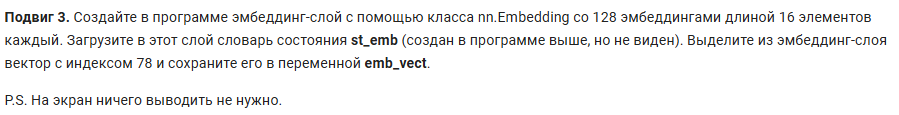

In [4]:
import torch
import torch.nn as nn


emb = nn.Embedding(128, 16)
emb.load_state_dict(st_emb) 

idx = torch.tensor(78, dtype=torch.long)
emb_vect = emb(idx)

TypeError: cannot assign 'torch.nn.modules.sparse.Embedding' as parameter 'weight' (torch.nn.Parameter or None expected)

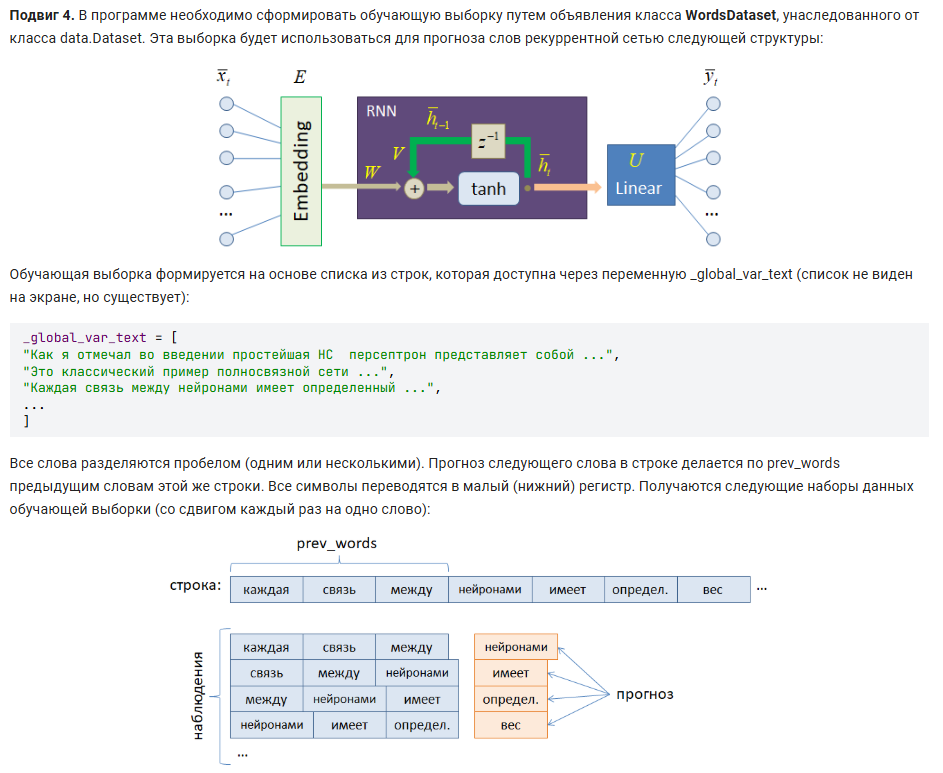

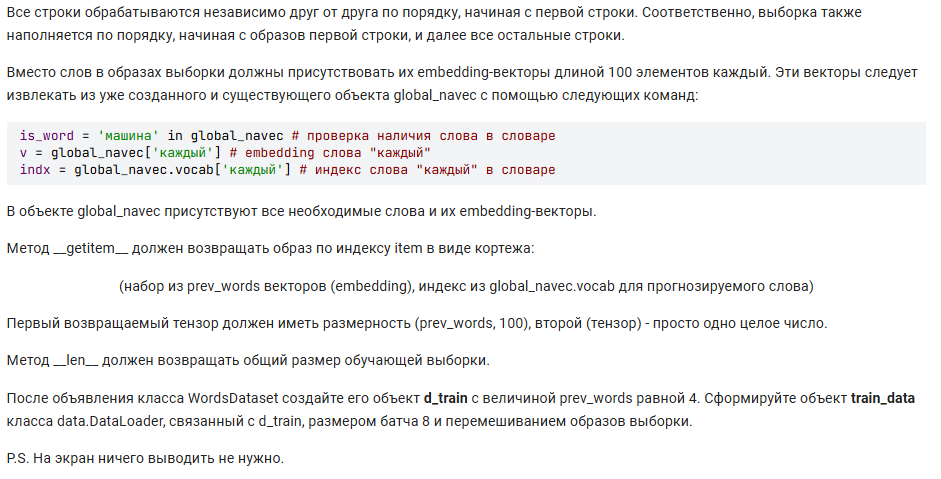

In [348]:
import torch
import torch.nn as nn
import torch.utils.data as data
import re
import navec
from navec import Navec


_global_var_text = [
"Как я отмечал во введении простейшая НС  представляет собой ",
"Это классический пример хорошей сети",
"Каждая связь между нейронами имеет определенный",
]

path = 'navec_hudlit_v1_12B_500K_300d_100q.tar'
global_navec = Navec.load(path)


class WordsDataset(data.Dataset):
    '''здесь много лишних атрибутов'''
    def __init__(self, navec_emb=None, prev_words=3):
        
        self.prev_words = prev_words
        self.navec_emb = navec_emb
        self.train_text = [self.clear_text(sentence) for sentence in _global_var_text]
        self.vocab = list(set([word for sentence in self.train_text for word in sentence]))
        self.int2word = dict(enumerate(self.vocab))
        self.word2int = {b: a for a, b in self.int2word.items()}
        self.len_vocab = len(self.vocab)
        
        self.x = []
        self.y = []
        for sentence in self.train_text:
            for i in range(prev_words, len(sentence)):
                # self.x.append([sentence[i-j] for j in range(prev_words, 0, -1)])
                # self.x.append(sentence[i-prev_words: i])
                # self.y.append(sentence[i])
                self.x.append([self.navec_emb[sentence[i-j]].tolist() for j in range(prev_words, 0, -1)])
                self.y.append(self.navec_emb.vocab[sentence[i]])

        self.x = torch.tensor(self.x)
        self.y = torch.tensor(self.y)
                

    @staticmethod
    def clear_text(text):
        text = text.replace('\ufeff', '')  # убираем первый невидимый символ
        text = text.replace('\n', ' ')
        text = re.sub(r'[^А-яA-z- ]', '', text)  # удаляем все неразрешенные символы
        text = text.lower().split()
        # text = [word for word in text if not word=='']
        text = [word for word in text if word in global_navec]
        return text


    def __getitem__(self, item):
        return self.x[item], self.y[item]

    
    def __len__(self):
        return len(self.x) - self.prev_words - 1


d_train = WordsDataset(prev_words=3, navec_emb=global_navec)
train_data = data.DataLoader(d_train, batch_size=6, shuffle=True)
d_train.x

tensor([[[-0.0204, -0.4305, -0.3130,  ..., -0.0266, -0.1075,  0.5631],
         [-0.3499, -0.3076, -0.2750,  ..., -0.5250,  0.1350,  0.2226],
         [-0.3472, -0.1470, -0.4983,  ...,  0.2750,  0.2647,  0.4108]],

        [[-0.3499, -0.3076, -0.2750,  ..., -0.5250,  0.1350,  0.2226],
         [-0.3472, -0.1470, -0.4983,  ...,  0.2750,  0.2647,  0.4108],
         [-0.0204, -0.4305, -0.3130,  ..., -0.5250,  0.1350,  0.2226]],

        [[-0.3472, -0.1470, -0.4983,  ...,  0.2750,  0.2647,  0.4108],
         [-0.0204, -0.4305, -0.3130,  ..., -0.5250,  0.1350,  0.2226],
         [-0.4001,  0.3622, -0.3973,  ..., -0.0571,  0.1050,  0.3030]],

        ...,

        [[ 0.1580,  0.0790,  0.0602,  ..., -0.1687,  0.5999,  0.4323],
         [ 0.4916,  0.0039, -0.0341,  ...,  0.3366,  0.3812, -0.0714],
         [ 0.3639, -0.5678, -0.2401,  ..., -0.1687,  0.5999,  0.4323]],

        [[ 0.4916,  0.0039, -0.0341,  ...,  0.3366,  0.3812, -0.0714],
         [ 0.3639, -0.5678, -0.2401,  ..., -0.1687,  0.

In [349]:
train_data = data.DataLoader(d_train, batch_size=6, shuffle=True)

In [350]:
it = iter(train_data)
a = next(it)

In [351]:
a[1].shape

torch.Size([6])

In [359]:
dir(d_train.navec_emb)

['__attributes__',
 '__class__',
 '__contains__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getitem__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__iter__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_repr_pretty_',
 'as_gensim',
 'dump',
 'get',
 'load',
 'meta',
 'pq',
 'sampled',
 'sim',
 'vocab']

In [361]:
d_train.navec_emb.pq.vectors

500002

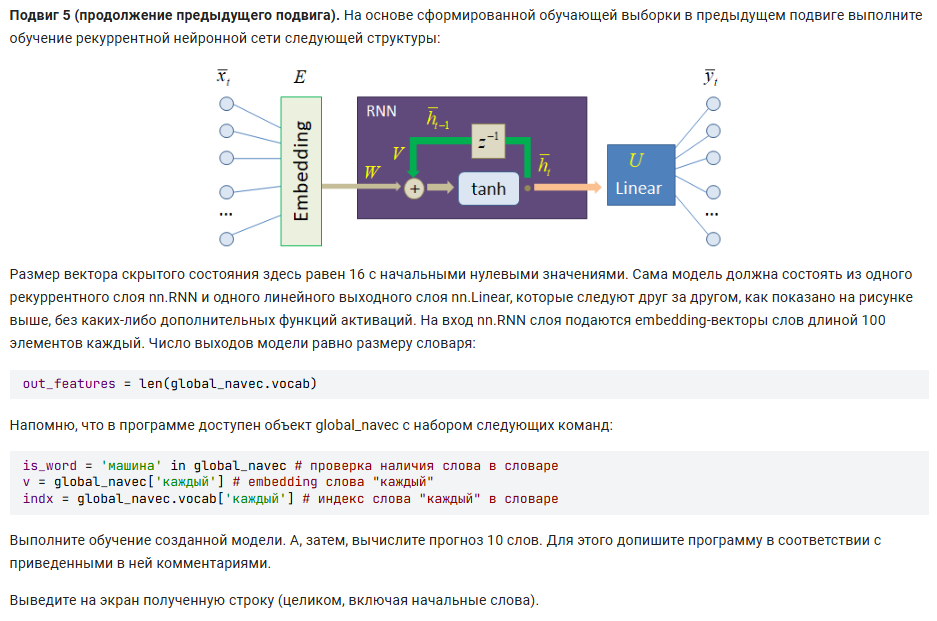

In [432]:
import torch
import torch.nn as nn
import torch.utils.data as data
import torch.optim as optim

# сюда копируйте класс WordsDataset, созданный на предыдущем занятии
class WordsDataset(data.Dataset):
    def __init__(self, navec_emb=None, prev_words=3):
        
        self.prev_words = prev_words
        self.navec_emb = navec_emb
        self.train_text = [self.clear_text(sentence) for sentence in _global_var_text]
        self.vocab = list(set([word for sentence in self.train_text for word in sentence]))
        self.int2word = dict(enumerate(self.vocab))
        self.word2int = {b: a for a, b in self.int2word.items()}
        self.len_vocab = len(self.vocab)
        
        self.x = []
        self.y = []
        for sentence in self.train_text:
            for i in range(prev_words, len(sentence)):
                self.x.append([self.navec_emb[sentence[i-j]].tolist() for j in range(prev_words, 0, -1)])
                self.y.append(self.navec_emb.vocab[sentence[i]])

        self.x = torch.tensor(self.x)
        self.y = torch.tensor(self.y)
                
    @staticmethod
    def clear_text(text):
        text = text.replace('\ufeff', '')  # убираем первый невидимый символ
        text = text.replace('\n', ' ')
        text = re.sub(r'[^А-яA-z- ]', '', text)  # удаляем все неразрешенные символы
        text = text.lower().split()
        # text = [word for word in text if not word=='']
        text = [word for word in text if word in global_navec]
        return text

    def __getitem__(self, item):
        return self.x[item], self.y[item]

    def __len__(self):
        return len(self.x)


# здесь объявляйте класс модели
class MyModel(nn.Module):
    def __init__(self, in_features, hidden_size, out_features):
        super().__init__()
        self.hidden_size = hidden_size
        # self.h = torch.zeros(self.hidden_size, dtype=torch.float32)
        self.rnn = nn.RNN(input_size=in_features, hidden_size=self.hidden_size, batch_first=True)
        self.linear = nn.Linear(hidden_size, out_features, bias=False)

    def forward(self, x):
        y, h = self.rnn(x)
        out = self.linear(h)
        return out


# сюда копируйте объекты d_train и train_data, созданные на предыдущем занятии
d_train = WordsDataset(prev_words=4, navec_emb=global_navec)
train_data = data.DataLoader(d_train, batch_size=8, shuffle=True)

model = MyModel(in_features=d_train.navec_emb.pq.dim, hidden_size=16, out_features=d_train.navec_emb.pq.vectors) # создайте объект модели для прогноза слов

optimizer = optim.Adam(model.parameters(), lr=0.01, weight_decay=0.0001) # создайте оптимизатор Adam с шагом обучения 0.01 и параметром weight_decay=0.0001
loss_func = nn.CrossEntropyLoss() # создайте функцию потерь кросс-энтропию для задачи многоклассовой классификации

epochs = 1 # число эпох обучения (в реальности нужно от 100 и более)
# переведите модель в режим обучения
model.train()

for _e in range(epochs):
    # с помощью цикла for переберите батчи из объекта train_data
    for x_train, y_train in train_data:
        # print(x_train.shape)
        predict = model(x_train).squeeze(0) # вычислите прогноз модели для x_train
        # print(predict.shape, y_train.shape)
        loss = loss_func(predict, y_train) # вычислите потери для predict и y_train

        # выполните один шаг обучения (градиентного спуска)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        

# переведите модель в режим эксплуатации
model.eval()
predict = "если что меня не похитили".lower().split()
total = 10 # число прогнозируемых слов (дополнительно к начальной фразе)

# выполните прогноз следующих total слов
for _ in range(total):
    words = predict[-d_train.prev_words:]
    embeddings = torch.tensor([d_train.navec_emb[word].tolist() for word in words]).unsqueeze(0)
    with torch.no_grad():
        predicted = model(embeddings)
    predicted_index = torch.argmax(predicted, dim=-1)
    predicted_word = d_train.navec_emb.vocab.words[predicted_index]
    predict.append(predicted_word)
    

# выведите полученную строку на экран
print(' '.join(predict))

если что меня не похитили гавайскими потреблению verlag взбаламученный надрывный сникерс тацинской дремлющими разбиваться домогательстве


In [430]:
d_train.navec_emb.vocab.words[110124]

'дискуссионного'

In [337]:
predicted_index

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [339]:
d_train.navec_emb.pq.dim

300

In [376]:
len(global_navec.vocab)

TypeError: object of type 'Vocab' has no len()

In [435]:
import torch
import torch.nn as nn
import torch.utils.data as data
import torch.optim as optim
import re


# сюда копируйте класс WordsDataset, созданный на предыдущем занятии
class WordsDataset(data.Dataset):
    def __init__(self, navec_emb=None, prev_words=3):
        
        self.prev_words = prev_words
        self.navec_emb = navec_emb
        self.train_text = [self.clear_text(sentence) for sentence in _global_var_text]
        self.vocab = list(set([word for sentence in self.train_text for word in sentence]))
        self.int2word = dict(enumerate(self.vocab))
        self.word2int = {b: a for a, b in self.int2word.items()}
        self.len_vocab = len(self.vocab)
        
        self.x = []
        self.y = []
        for sentence in self.train_text:
            for i in range(prev_words, len(sentence)):
                self.x.append([self.navec_emb[sentence[i-j]].tolist() for j in range(prev_words, 0, -1)])
                self.y.append(self.navec_emb.vocab[sentence[i]])

        self.x = torch.tensor(self.x)
        self.y = torch.tensor(self.y)
                
    @staticmethod
    def clear_text(text):
        text = text.replace('\ufeff', '')  # убираем первый невидимый символ
        text = text.replace('\n', ' ')
        text = re.sub(r'[^А-яA-z- ]', '', text)  # удаляем все неразрешенные символы
        text = text.lower().split()
        # text = [word for word in text if not word=='']
        text = [word for word in text if word in global_navec]
        return text

    def __getitem__(self, item):
        return self.x[item], self.y[item]

    def __len__(self):
        return len(self.x)


# здесь объявляйте класс модели
class MyModel(nn.Module):
    def __init__(self, in_features, hidden_size, out_features):
        super().__init__()
        self.hidden_size = hidden_size
        # self.h = torch.zeros(self.hidden_size, dtype=torch.float32)
        self.rnn = nn.RNN(input_size=in_features, hidden_size=self.hidden_size, batch_first=True)
        self.linear = nn.Linear(hidden_size, out_features, bias=False)

    def forward(self, x):
        y, h = self.rnn(x)
        out = self.linear(h)
        return out


# сюда копируйте объекты d_train и train_data, созданные на предыдущем занятии
d_train = WordsDataset(prev_words=4, navec_emb=global_navec)
train_data = data.DataLoader(d_train, batch_size=8, shuffle=True)

model = MyModel(in_features=300, hidden_size=16, out_features=500_002) # создайте объект модели для прогноза слов

# создайте оптимизатор Adam с шагом обучения 0.01 и параметром weight_decay=0.0001
optimizer = optim.Adam(model.parameters(), lr=0.01, weight_decay=0.0001) 

loss_func = nn.CrossEntropyLoss() # создайте функцию потерь кросс-энтропию для задачи многоклассовой классификации

epochs = 1 # число эпох обучения (в реальности нужно от 100 и более)
# переведите модель в режим обучения
model.train()

for _e in range(epochs):
    # с помощью цикла for переберите батчи из объекта train_data
    for x_train, y_train in train_data:
        # print(x_train.shape)
        predict = model(x_train).squeeze(0) # вычислите прогноз модели для x_train
        # print(predict.shape, y_train.shape)
        loss = loss_func(predict, y_train) # вычислите потери для predict и y_train

        # выполните один шаг обучения (градиентного спуска)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        

# переведите модель в режим эксплуатации
model.eval()
predict = "Такими были первые нейронные сети предложенные".lower().split()
total = 10 # число прогнозируемых слов (дополнительно к начальной фразе)

# выполните прогноз следующих total слов
for _ in range(total):
    words = predict[-d_train.prev_words:]
    embeddings = torch.tensor([d_train.navec_emb[word].tolist() for word in words]).unsqueeze(0)
    with torch.no_grad():
        predicted = model(embeddings)
    predicted_index = torch.argmax(predicted, dim=-1).item()
    print(predicted_index)
    predicted_word = d_train.navec_emb.vocab.words[predicted_index]
    predict.append(predicted_word)
    

# выведите полученную строку на экран
print(' '.join(predict))

440521


KeyError: 440521

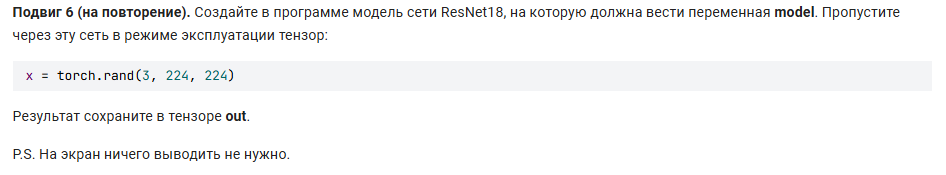

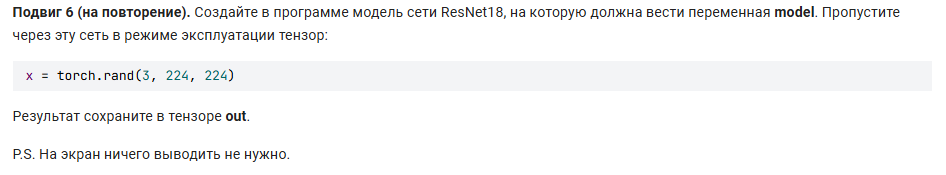

In [437]:
import torch
import torch.nn as nn
from torchvision import models

x = torch.rand(3, 224, 224) # тензор x в программе не менять
model = models.resnet18()

# здесь продолжайте программу
model.eval()
out = model(x.unsqueeze(0))